Measure the gap between the average head and the head in the wells for different pumping rates and different settings.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from Components.System import SimpleSquareExample
from Components.Model import SquareCoarseModel
from Components.Controllers import LTI_LQRc_RHG

In [3]:
# Reload scripts when executed
%load_ext autoreload
%autoreload 2

np.set_printoptions(linewidth=np.inf)

In [4]:
parameter_file = "Components/Setup/aquifer_parameters.json"

In [5]:
# Initialize System and Model
system = SimpleSquareExample(parameter_file, boundary_condition="Constant Head")
model = SquareCoarseModel(parameter_file, boundary_condition="Constant Head")

# Study trajectory over increasingly large horizon

In [6]:
K_range = range(5,50,10)

In [13]:
traj = []
for K in K_range:
    # Initialize Controller
    Q_v, R_v,R_v_minus, M_v, L_v = model.get_cost_matrices("correct_cost")
    controller = LTI_LQRc_RHG(
        parameter_file,
        model.A.toarray(), [B.toarray() for B in model.B_v], model.C,
        model.H_x, model.h_x, model.H_u_v, model.h_u_v,
        model.H_xu_x, model.H_xu_u, model.h_xu,
        Q_v, R_v,R_v_minus, M_v, L_v,
        solver='fbrs',
        overwrite_time_horizon=K
    )
    inputs, x_pred = controller.step(model.state-0.3)
    traj.append(model.select_wells(x_pred))

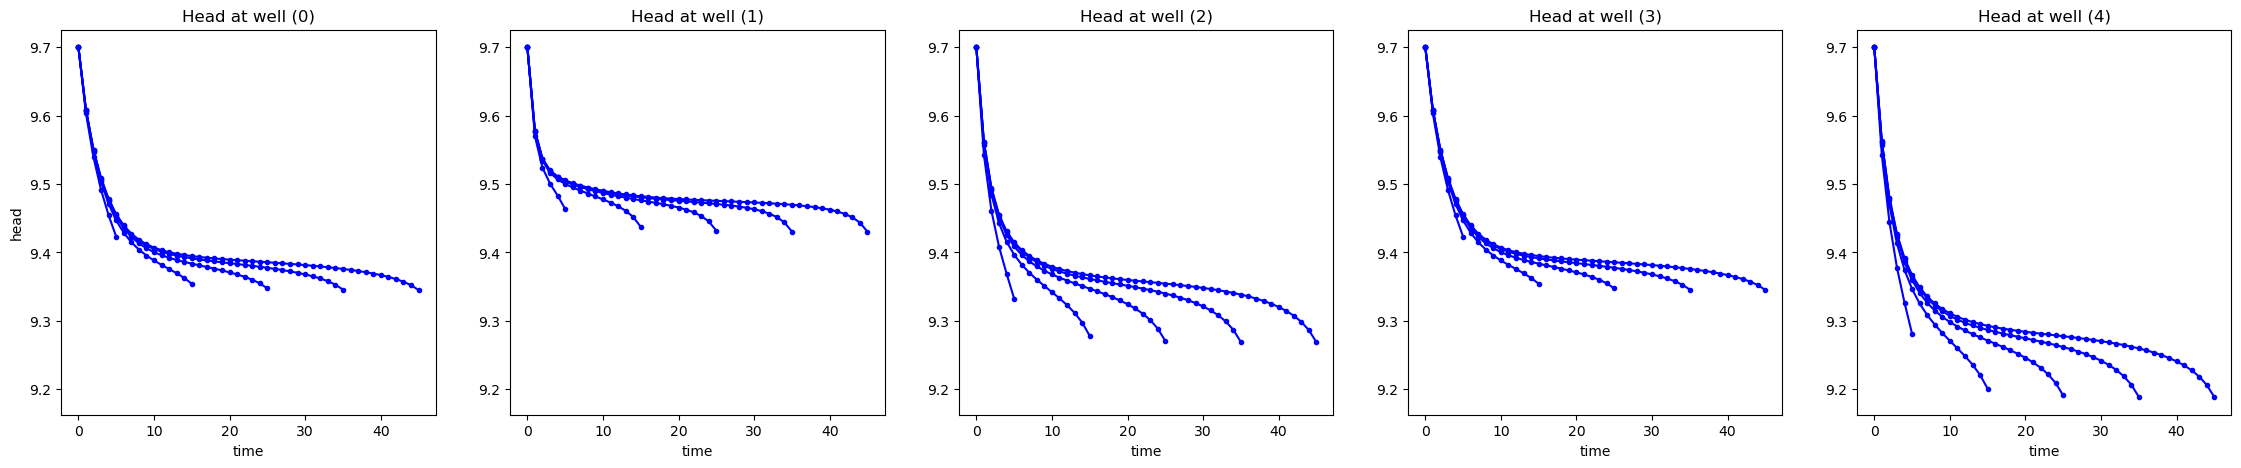

In [14]:
fig_h = plt.figure(figsize=(25+3,5))
ax_h = None
for ii in range(5):
    ax_h = fig_h.add_subplot(1, 5, ii+1, sharey=ax_h)
    ttl = f"Head at well ({ii})"
    ax_h.set_title(ttl)
    ax_h.set_xlabel("time")
    if ii == 0:
        ax_h.set_ylabel("head")
    for k, K in enumerate(K_range):
        t = np.linspace(0,K, K+1)
        ax_h.plot(traj[k][ii,:], "b.-")